In [1]:
import pandas as pd
import matplotlib.pyplot as plt

pd.set_option("display.max_columns", None)

df = pd.read_csv("data/WA_Fn-UseC_-HR-Employee-Attrition.csv")
df = df.drop(columns=["EmployeeCount", "Over18", "StandardHours"])

df["saiu"] = (df["Attrition"] == "Yes").astype(int)
taxa_geral = df["saiu"].mean() * 100
print(f"Turnover geral: {taxa_geral:.1f}%")

Turnover geral: 16.1%


In [2]:
def turnover_por(coluna):
    tabela = (
        df.groupby(coluna, observed=True)
        .agg(funcionarios=("saiu", "size"),
             sairam=("saiu", "sum"),
             turnover_pct=("saiu", "mean"))
    )
    tabela["turnover_pct"] = (tabela["turnover_pct"] * 100).round(1)
    return tabela


def grafico(tabela, titulo, ordenar=True):
    t = tabela.sort_values("turnover_pct") if ordenar else tabela.iloc[::-1]
    fig, ax = plt.subplots(figsize=(8, 0.45 * len(t) + 1.2))
    barras = ax.barh(t.index.astype(str), t["turnover_pct"], color="#3b6fb6", height=0.6)
    ax.axvline(taxa_geral, color="#888888", linestyle="--", linewidth=1)
    ax.text(taxa_geral, len(t) - 0.4, f" média {taxa_geral:.1f}%", color="#555555", fontsize=9)
    ax.bar_label(barras, fmt="%.1f%%", padding=3, fontsize=9)
    ax.set_title(titulo, loc="left")
    ax.set_xlabel("Turnover (%)")
    ax.spines[["top", "right"]].set_visible(False)
    plt.tight_layout()
    plt.show()

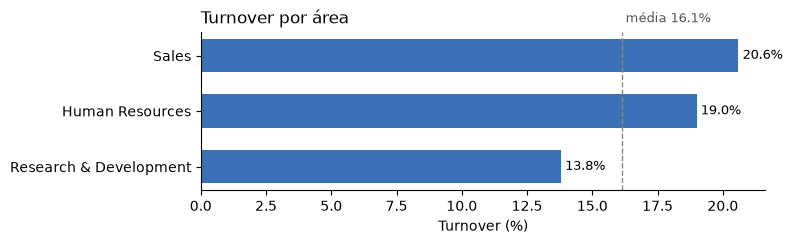

,funcionarios,sairam,turnover_pct
Department,,,
Human Resources,63,12,19.0
Research & Development,961,133,13.8
Sales,446,92,20.6


In [3]:
area = turnover_por("Department")
grafico(area, "Turnover por área")
area

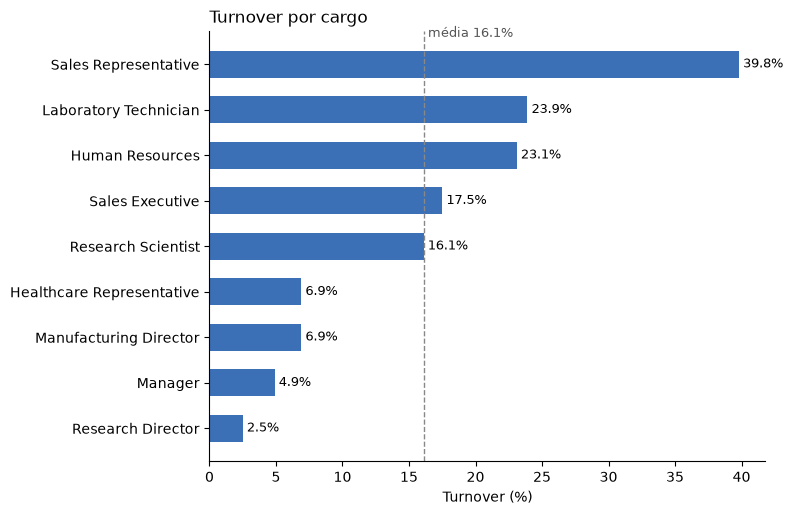

,funcionarios,sairam,turnover_pct
JobRole,,,
Sales Representative,83,33,39.8
Laboratory Technician,259,62,23.9
Human Resources,52,12,23.1
Sales Executive,326,57,17.5
Research Scientist,292,47,16.1
Healthcare Representative,131,9,6.9
Manufacturing Director,145,10,6.9
Manager,102,5,4.9
Research Director,80,2,2.5


In [4]:
cargo = turnover_por("JobRole")
grafico(cargo, "Turnover por cargo")
cargo.sort_values("turnover_pct", ascending=False)

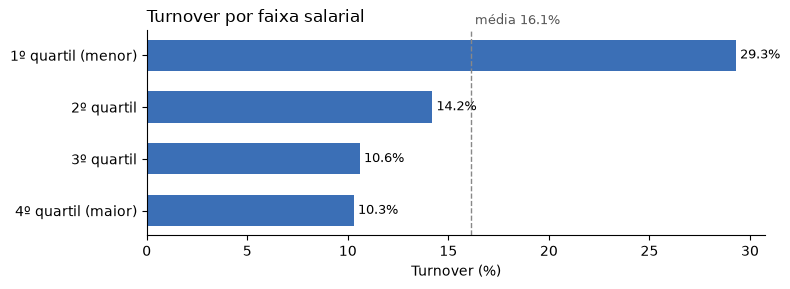

Salário mediano de quem ficou x quem saiu:
Attrition
No     5204.0
Yes    3202.0
Name: MonthlyIncome, dtype: float64


,funcionarios,sairam,turnover_pct
faixa_salarial,,,
1º quartil (menor),369,108,29.3
2º quartil,366,52,14.2
3º quartil,367,39,10.6
4º quartil (maior),368,38,10.3


In [5]:
df["faixa_salarial"] = pd.qcut(
    df["MonthlyIncome"], 4,
    labels=["1º quartil (menor)", "2º quartil", "3º quartil", "4º quartil (maior)"]
)
salario = turnover_por("faixa_salarial")
grafico(salario, "Turnover por faixa salarial", ordenar=False)

print("Salário mediano de quem ficou x quem saiu:")
print(df.groupby("Attrition")["MonthlyIncome"].median())
salario

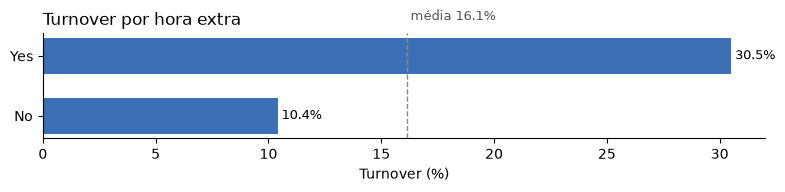

,funcionarios,sairam,turnover_pct
OverTime,,,
No,1054,110,10.4
Yes,416,127,30.5


In [6]:
hora_extra = turnover_por("OverTime")
grafico(hora_extra, "Turnover por hora extra")
hora_extra

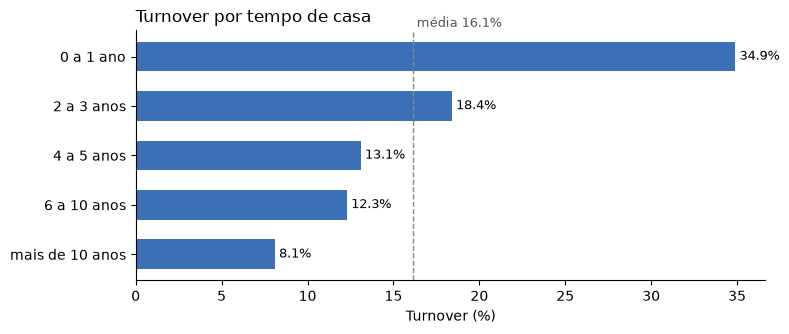

,funcionarios,sairam,turnover_pct
tempo_casa,,,
0 a 1 ano,215,75,34.9
2 a 3 anos,255,47,18.4
4 a 5 anos,306,40,13.1
6 a 10 anos,448,55,12.3
mais de 10 anos,246,20,8.1


In [7]:
df["tempo_casa"] = pd.cut(
    df["YearsAtCompany"],
    bins=[-1, 1, 3, 5, 10, 40],
    labels=["0 a 1 ano", "2 a 3 anos", "4 a 5 anos", "6 a 10 anos", "mais de 10 anos"]
)
tempo = turnover_por("tempo_casa")
grafico(tempo, "Turnover por tempo de casa", ordenar=False)
tempo

In [8]:
cruzado = (
    df.groupby(["OverTime", "faixa_salarial"], observed=True)["saiu"]
    .mean().mul(100).round(1)
    .unstack()
)
cruzado

faixa_salarial,1º quartil (menor),2º quartil,3º quartil,4º quartil (maior)
OverTime,,,,
No,17.5,10.0,7.0,7.2
Yes,58.5,26.0,19.3,18.1


## Achados

- **Hora extra** é o fator mais forte: 30,5% de turnover contra 10,4% sem hora extra.
- **Salário baixo**: o 1º quartil (até 2.911/mês) tem 29,3%; as outras faixas ficam entre 10% e 14%.
- **Combinação crítica**: hora extra + 1º quartil salarial = 58,5% de turnover.
- **Primeiro ano** é o período de maior risco: 34,9%, caindo para 8,1% depois de 10 anos.
- **Cargo pesa mais que área**: Sales Representative tem 39,8%; Research Director, 2,5%.